### Use case demonstration for Case A

In this Jupyter Notebook we are going to illustrate multiple computer models to analyse dummy-data and tumor-growth data. This notebook uses an use case demonstration format to sketch how someone might implement these models. 

The table of contents:
- Workshop 1: the SIR-model.
- Workshop 2: ODE-solvers
- Workshop 3: Optimalization
- Workshop 4: Comparing the models
- Conclusion: Which model is the best?

First we need to set up the right dependencies so that we can read the input-file and to use parameters to plot the desired model in a graph.  

**!! Please note that you do need the ipykernel-package installed in your IDE to run these code chunks shown below !!**

In [24]:
import pandas as pd # file reading and data manipulation
import matplotlib.pyplot as plt # for the plotting
from main import DynamicModelling # import the `DynamicModelling` class from the main.py

data = pd.read_csv('generated_data/sir_dummy_dataset.csv') # generated data
dm = DynamicModelling(data) # create an instance of the `DynamicModelling` class


### Workshop 1: Running the SIR-model. 

We are use to the same parameter-value configurations as shown in the `main.py` script. These standard parameters are:

B, beta = 0.35 and y, gamma = 0.10.

Now we are going to call the class from the `main.py` to make the plot:

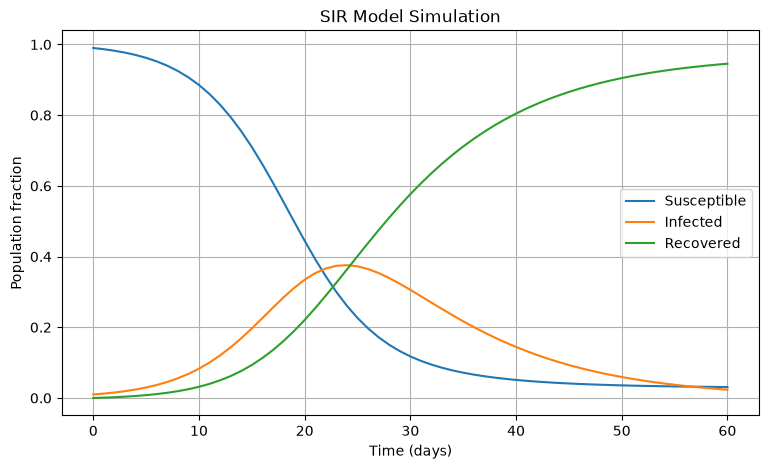

In [25]:
ts, Ss, Is, Rs = dm.SIR_model() # Calling the SIR_model from the `DynamicModelling` 

plt.figure(figsize=(9, 5))
plt.plot(ts, Ss, label="Susceptible")
plt.plot(ts, Is, label="Infected")
plt.plot(ts, Rs, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Population fraction")
plt.title("SIR Model Simulation")
plt.legend()
plt.grid()
plt.show()

#### Looking at the plot

The plot shows a correlation between the suspectibale, infected and recovered-trendline. The more people recover, the less people there are that are suspectible to catch the desease. We are looking at dummy-data here, so it is wrong to assume this conclusion to be realistic. But it is a nice way of experimenting with different models to look at their output. 

We can also plot a certain region alone using the SIR-model. We are looking at an example below. 

Looking at the dummy-data, we can see that the data is divided by regions. In this example we are curious about the north region.

Let's plot the graph.

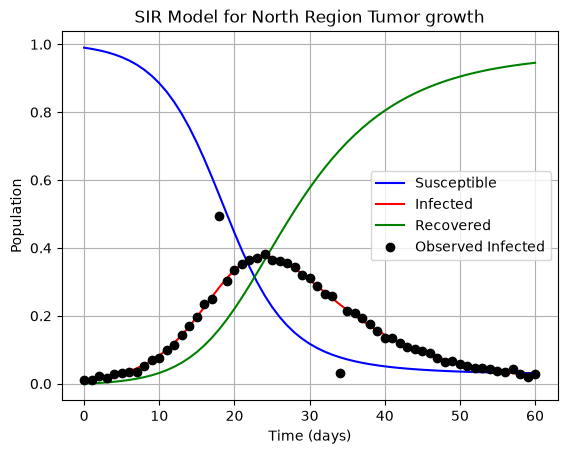

In [26]:
dm.plot_SIR(region="Region_North") # Calling north-region plot SIR

As you can see, this plot also contains the "real" data-values, shown in black. There are two visible outliers, but in general they do not need seem to influence the trendline. 

Showing you this example, we can conclude that there are many ways to implement your own parameters to models such as the SIR-model. 

### Workshop 3: Optimization 

We are going to look at optimizing a real (non-generated) tumor growth model. We are using Random Search to find the growth parameter. This parameter finds deviations between the model and the data and makes it as small as possible. We are also trying to minimize the Mean Squared Error (MSE).

#### Requirements for this demo

* `main.py` with the `DynamicModelling` class
* input-file found under `generated_data/peerj-07-6983-s001.csv`
* `Pandas` and `Matplotlib`


#### Setup 

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import main
import importlib

importlib.reload(main) # reloads the main.py to ensure the latest version is used

data = pd.read_csv('generated_data/peerj-07-6983-s001.csv') # Reference can be found in the README.
dm = main.DynamicModelling(data) # Initializing the model

#### Running the model

We apply the exponential growth model to the tumor dataset. The differential equations are solved using the Runge-Kutta ODE-solver.

Random Search adjusts the model parameters to minimize the MSE for each treatment group (`TRT`).

Now it's time to run the model optimization.



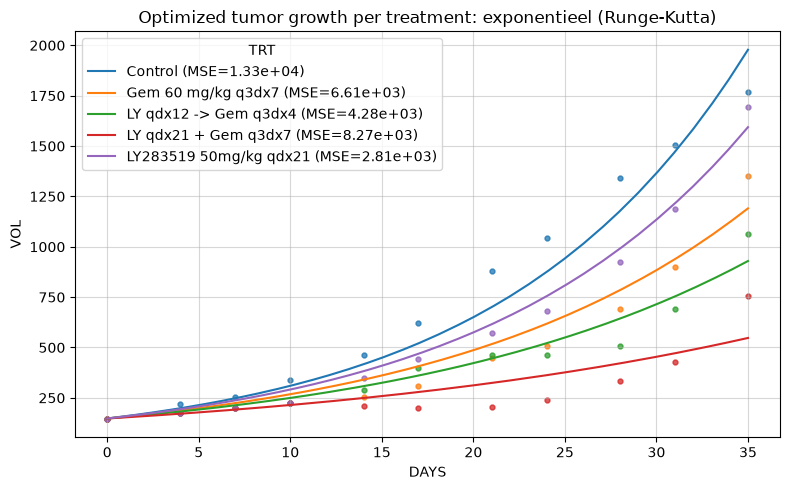

In [28]:
results = dm.optimization(
    model="exponentieel",
    method="Runge-Kutta",
    groupby="TRT",
    ground="DAYS",
    references=["VOL"],
    plot=True
)

### Results interpretation 

The optimization results show differences in tumor growth between treatment groups. The control group demonstartes the strongest tumor growth, while the LY QDX + Gem treatment show the lowest predicted tumor growth. 

Regarding model performance, the LY283... 50mg/kg treatment group has the lowest MSE. This indicates the best fit between observed data and the predicted exponential growth curve. The control group has the highest MSE.

These results show that a lower MSE does not necessarily mean a more effective treatment. MSE measures how accuratly the model describes the observed data, rather tgan the effectiveness of a treatment. 

Overall the exponential model provides a useful way to compare tumor growth patterns. However, further statistical analysis would be required to show real significance. 